In [6]:
from roboflow import Roboflow

rf = Roboflow(api_key="8o4XxfU2j9AjEbiDVd0p")
project = rf.workspace("deeplearning-fcrat").project("hard-hat-workers-mawpn")

print("Доступные версии для скачивания:")
for v in project.versions():
    print(f" - Версия: {v.version}, Название: {v.name}")

loading Roboflow workspace...
loading Roboflow project...
Доступные версии для скачивания:


In [12]:
from roboflow import Roboflow

API_KEY = "8o4XxfU2j9AjEbiDVd0p"
rf = Roboflow(api_key=API_KEY)

try:
    # Используем проект "hard-hat-sample"
    project = rf.workspace("rndmgtu-t3cfs").project("hard-hat-sample-2dv9h")

    # Проверяем доступные версии
    versions = project.versions()
    print("Доступные версии:", [v.version for v in versions])

    if versions:
        # Скачиваем первую доступную версию
        dataset = project.version(versions[0].version).download("yolov8")
        print(" УСПЕХ! Датасет скачан в:", dataset.location)
    else:
        print(" Версии не найдены, пробуем другой проект...")

        # Резервный вариант
        project2 = rf.workspace("licence-plate-obb").project("hard-hat-sample-ym3sl")
        dataset = project2.version(1).download("yolov8")
        print(" УСПЕХ (резерв)! Датасет скачан в:", dataset.location)

except Exception as e:
    print(" Ошибка:", e)
    print("Другой датасет. Например, 'hard-hat-workers' от joseph-nelson (версия 1 или 2).")

loading Roboflow workspace...
loading Roboflow project...
Доступные версии: ['2', '1']
 УСПЕХ! Датасет скачан в: /content/Hard-Hat-Sample-2


In [13]:
from ultralytics import YOLO
import os

# 1. Путь к файлу data.yaml
yaml_path = "/content/Hard-Hat-Sample-2/data.yaml"
print("Проверка data.yaml:", os.path.exists(yaml_path))

# 2. Обучаем МАЛЕНЬКУЮ модель (YOLOv8n)
print("\n=== Обучение YOLOv8n (маленькая) ===")
model_n = YOLO('yolov8n.pt')
results_n = model_n.train(
    data=yaml_path,
    epochs=15,
    imgsz=640,
    batch=16,
    patience=10,
    project='/content/runs',
    name='n_model',
    seed=42,
    device=0            # Использовать GPU
)

# 3. Обучаем СРЕДНЮЮ модель (YOLOv8s)
print("\n=== Обучение YOLOv8s (средняя) ===")
model_s = YOLO('yolov8s.pt')
results_s = model_s.train(
    data=yaml_path,
    epochs=15,
    imgsz=640,
    batch=16,
    patience=10,
    project='/content/runs',
    name='s_model',
    seed=42,
    device=0
)

print("\n ОБУЧЕНИЕ ЗАВЕРШЕНО!")

Проверка data.yaml: True

=== Обучение YOLOv8n (маленькая) ===
Ultralytics 8.4.204 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Hard-Hat-Sample-2/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=15, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale

In [19]:
import time
from ultralytics import YOLO
import os

best_n = YOLO('/content/runs/n_model/weights/best.pt')
best_s = YOLO('/content/runs/s_model/weights/best.pt')

def measure_speed(model):
    model.to(0)
    img_path = '/content/Hard-Hat-Sample-2/test/images/' + os.listdir('/content/Hard-Hat-Sample-2/test/images')[0]
    model.predict(img_path, verbose=False)
    t0 = time.time()
    for _ in range(10):
        model.predict(img_path, verbose=False)
    return round((time.time() - t0) / 10 * 1000, 1)

print(f"Скорость YOLOv8n на GPU: {measure_speed(best_n)} мс")
print(f"Скорость YOLOv8s на GPU: {measure_speed(best_s)} мс")

Скорость YOLOv8n на GPU: 18.9 мс
Скорость YOLOv8s на GPU: 43.4 мс


In [15]:
import time
from ultralytics import YOLO

best_n = YOLO('/content/runs/n_model/weights/best.pt')
best_s = YOLO('/content/runs/s_model/weights/best.pt')

# Замер скорости
def measure_speed(model):
    model.to(0)
    img_path = '/content/Hard-Hat-Sample-2/test/images/' + os.listdir('/content/Hard-Hat-Sample-2/test/images')[0]
    model.predict(img_path, verbose=False)
    t0 = time.time()
    for _ in range(10):
        model.predict(img_path, verbose=False)
    return round((time.time() - t0) / 10 * 1000, 1)

print(f"Скорость YOLOv8n на GPU: {measure_speed(best_n)} мс")
print(f"Скорость YOLOv8s на GPU: {measure_speed(best_s)} мс")

# Экспорт модели (YOLOv8n) в ONNX
print("\nЭкспорт в ONNX...")
onnx_path = best_n.export(format='onnx', imgsz=640, simplify=True)
print(f" ONNX сохранен: {onnx_path}")

Скорость YOLOv8n на GPU: 46.3 мс
Скорость YOLOv8s на GPU: 19.1 мс

Экспорт в ONNX...
Ultralytics 8.4.204 🚀 Python-3.13.16 torch-2.14.1+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
Model summary (fused): 73 layers, 3,133,193 parameters, 0 gradients, 8.6 GFLOPs

PyTorch: starting from '/content/runs/n_model/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 7, 8400) (6.2 MB)
requirements: Ultralytics requirements ['onnx>=1.12.0,<2.0.0', 'onnxruntime', 'onnxslim>=0.1.82'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 12 packages in 203ms
Prepared 4 packages in 518ms
Installed 4 packages in 33ms
 + colorama==0.4.6
 + onnx==1.23.2
 + onnxruntime==1.31.1
 + onnxslim==0.1.99

requirements: AutoUpdate success ✅ 1.2s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take e

In [16]:
import os
import io
import uvicorn
import threading
import time
import requests
import json
from fastapi import FastAPI, File, UploadFile, APIRouter
from PIL import Image
from ultralytics import YOLO

# 1. Создаем эндпоинт
router = APIRouter()
DETECTOR = YOLO('/content/runs/n_model/weights/best.pt')

@router.post('/detect')
async def detect(file: UploadFile = File(...), conf: float = 0.25):
    image = Image.open(io.BytesIO(await file.read())).convert('RGB')
    result = DETECTOR.predict(image, conf=conf, verbose=False)[0]
    boxes = []
    for b in result.boxes:
        x1, y1, x2, y2 = [round(float(v), 1) for v in b.xyxy[0]]
        boxes.append({
            'class': DETECTOR.names[int(b.cls)],
            'confidence': round(float(b.conf), 3),
            'box': [x1, y1, x2, y2]
        })
    return {'width': image.width, 'height': image.height, 'count': len(boxes), 'boxes': boxes}

# 2. Создаем приложение и подключаем эндпоинт
app = FastAPI()
app.include_router(router)

# 3. Запускаем сервер в фоне
def run_server():
    uvicorn.run(app, host="127.0.0.1", port=8000, log_level="error")

threading.Thread(target=run_server, daemon=True).start()
time.sleep(5) # Ждем загрузки

# 4. Отправляем тестовую картинку
img_dir = '/content/Hard-Hat-Sample-2/test/images/'
img_name = os.listdir(img_dir)[0]
img_path = os.path.join(img_dir, img_name)

print(f"Отправляем картинку: {img_name}")
with open(img_path, 'rb') as f:
    files = {'file': (img_name, f, 'image/jpeg')}
    response = requests.post('http://127.0.0.1:8000/detect', files=files)

print("\n--- ОТВЕТ СЕРВИСА ---")
print(f"HTTP Статус: {response.status_code}")
print(json.dumps(response.json(), indent=4, ensure_ascii=False))

Отправляем картинку: 000073_jpg.rf.omTgaen6ihwgXQ3WtYQt.jpg

--- ОТВЕТ СЕРВИСА ---
HTTP Статус: 200
{
    "width": 416,
    "height": 416,
    "count": 9,
    "boxes": [
        {
            "class": "helmet",
            "confidence": 0.903,
            "box": [
                326.8,
                63.7,
                416.0,
                144.2
            ]
        },
        {
            "class": "helmet",
            "confidence": 0.833,
            "box": [
                263.8,
                53.2,
                295.6,
                86.2
            ]
        },
        {
            "class": "helmet",
            "confidence": 0.788,
            "box": [
                97.8,
                40.2,
                153.5,
                90.2
            ]
        },
        {
            "class": "helmet",
            "confidence": 0.7,
            "box": [
                294.0,
                84.7,
                363.0,
                141.5
            ]
      

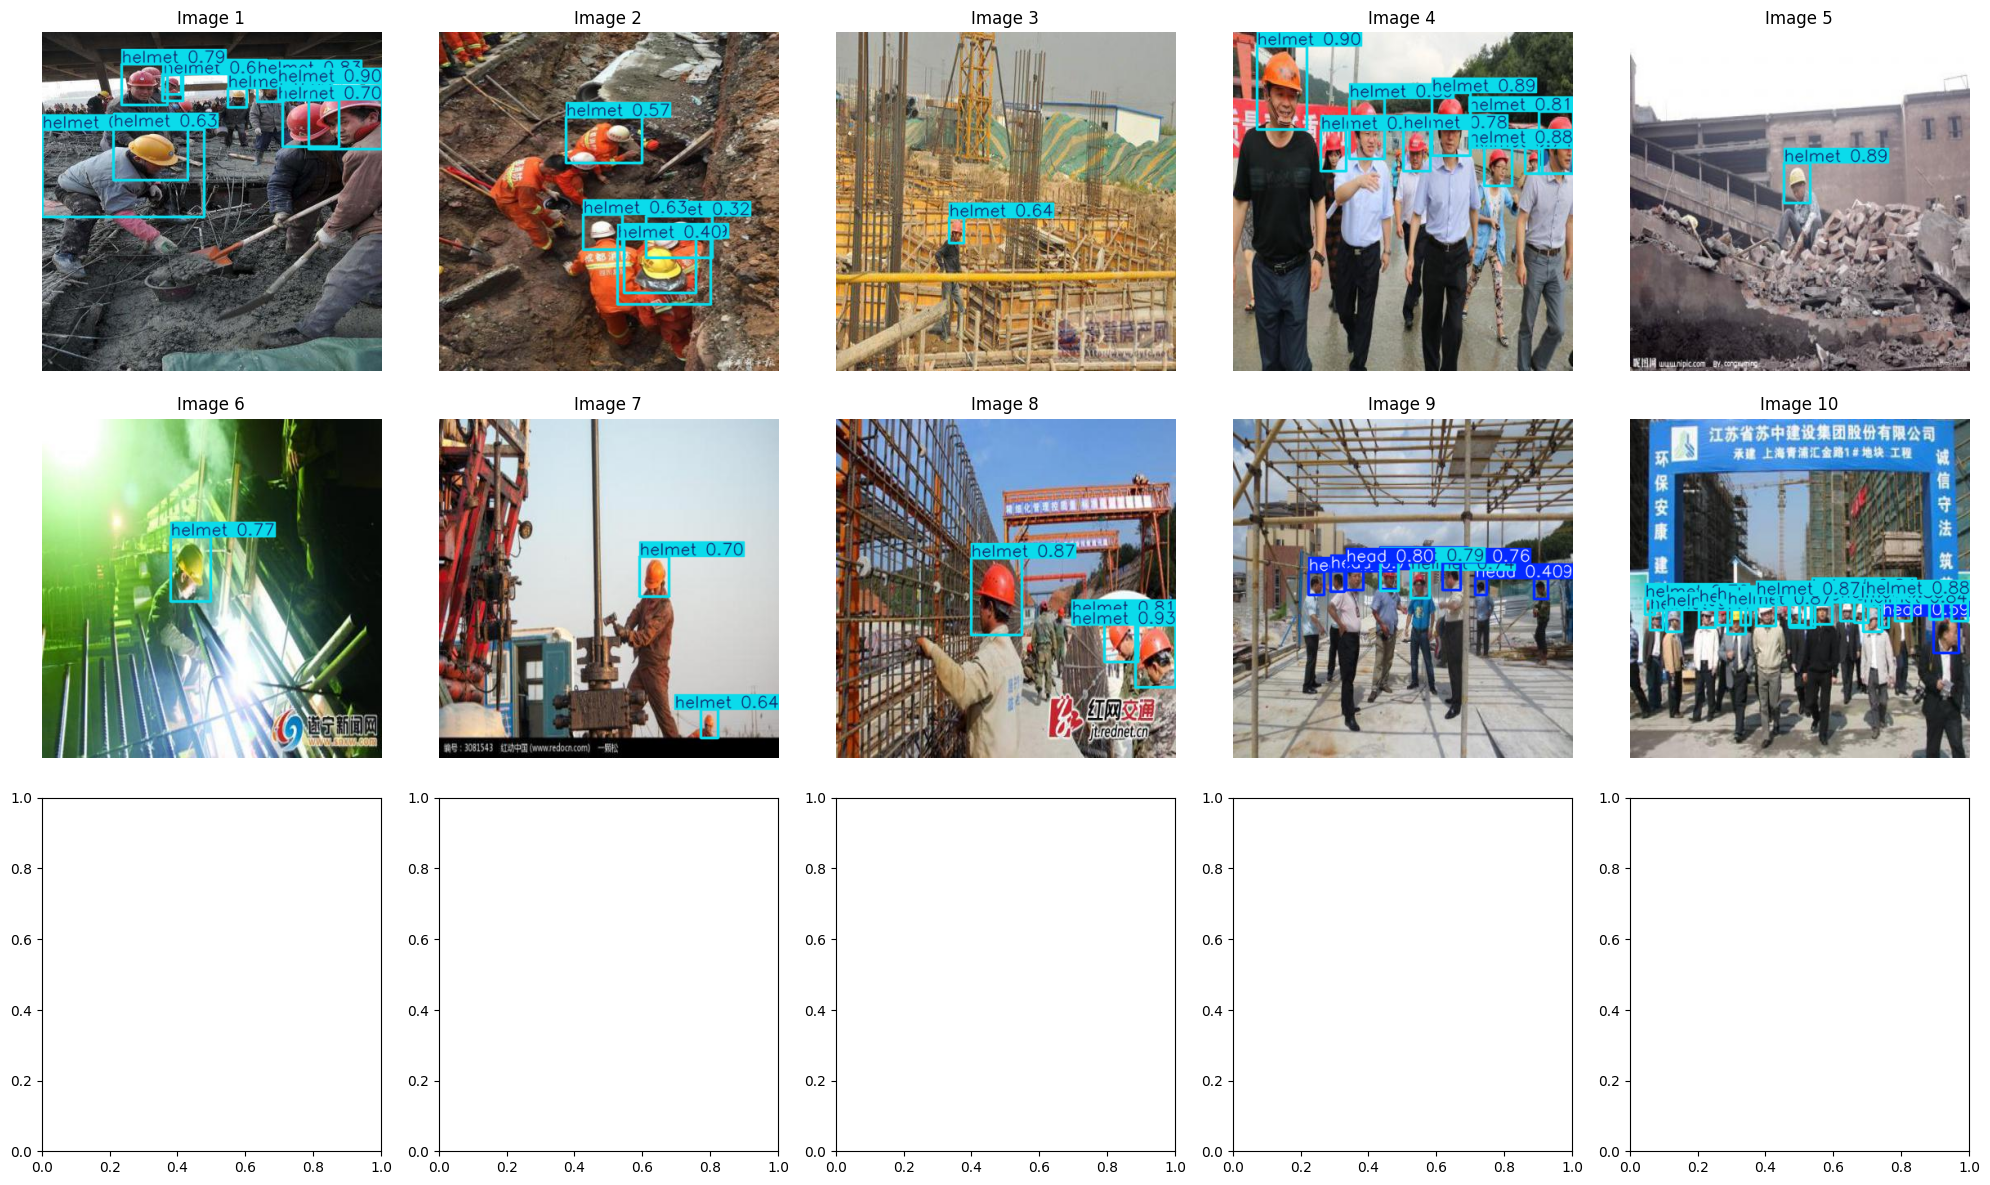

 Сетка ошибок сохранена как errors_grid.png 


In [18]:
import glob
import matplotlib.pyplot as plt
from ultralytics import YOLO
import os

# Загружаем модель
best_n = YOLO('/content/runs/n_model/weights/best.pt')

# Берем 10 картинок
test_images = glob.glob('/content/Hard-Hat-Sample-2/test/images/*.jpg')[:15]

# Создаем сетку 3x5
fig, axes = plt.subplots(3, 5, figsize=(20, 12))
axes = axes.flatten()

for i, img_path in enumerate(test_images):
    # Делаем предсказание с порогом уверенности 0.25
    results = best_n.predict(img_path, conf=0.25, verbose=False)
    # Рисуем рамки на картинке
    res_plotted = results[0].plot()

    # Отображаем
    axes[i].imshow(res_plotted[..., ::-1]) # Конвертируем BGR в RGB
    axes[i].set_title(f"Image {i+1}")
    axes[i].axis('off')

plt.tight_layout()
plt.savefig('errors_grid.png', dpi=150)
plt.show()
print(" Сетка ошибок сохранена как errors_grid.png ")